# 04 · Comparing representation stabilization (CKA) with Neural Collapse

Combines the outputs of the previous notebooks to answer the central question of the thesis: **does the network's internal representation stop changing before, together with, or after the Neural Collapse geometry has formed?** It also locates the start of the Terminal Phase of Training (TPT).

**Inputs** (CSV files, found automatically in the folders listed in the config cell)
- `CKA_results.csv` – linear CKA of the `avgpool` features with the epoch-350 features (notebook 02)
- `NC_results.csv` – NC1–NC4 per checkpoint (notebook 03)
- `training_history.csv` – per-epoch training accuracy (notebook 01), used to locate the TPT

**Conventions**
- All stabilization epochs use the *strict* rule: the first checkpoint from which the criterion holds for every later checkpoint.
- NC metrics (lower = more collapsed): value ≤ 1.2 × final value; NC4: value ≤ 0.01 (see notebook 03).
- CKA (higher = closer to the final representation): value ≥ 0.95 and ≥ 0.99.
- TPT start: first epoch with 100 % *running* training accuracy (accumulated over the augmented batches of that epoch).

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Load results

In [2]:
REQUIRED = ["CKA_results.csv", "NC_results.csv", "training_history.csv"]
OUTPUT_DIR = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path(".")


cka_df = pd.read_csv("/kaggle/input/notebooks/parinazghasemi/02-compute-cka/CKA_results.csv")
nc_df = pd.read_csv("/kaggle/input/notebooks/parinazghasemi/03-compute-neural-collapse/NC_results.csv")
history = pd.read_csv("/kaggle/input/notebooks/parinazghasemi/train-more-epochs/training_history.csv")

df = (
    nc_df.merge(cka_df[["epoch", "CKA"]], on="epoch", how="inner")
    .sort_values("epoch")
    .reset_index(drop=True)
)
print("Merged checkpoints:", len(df), "| epochs", df["epoch"].min(), "-", df["epoch"].max())

TPT_EPOCH = int(history.loc[history["train_acc"] >= 100.0, "epoch"].min())
print("TPT start (first epoch with 100% training accuracy):", TPT_EPOCH)

Merged checkpoints: 113 | epochs 1 - 350
TPT start (first epoch with 100% training accuracy): 313


## Stabilization epochs

In [3]:
def strict_below(epochs, values, threshold):
    epochs, values = np.asarray(epochs), np.asarray(values)
    for i in range(len(values)):
        if np.all(values[i:] <= threshold):
            return int(epochs[i])
    return None


def strict_above(epochs, values, threshold):
    epochs, values = np.asarray(epochs), np.asarray(values)
    for i in range(len(values)):
        if np.all(values[i:] >= threshold):
            return int(epochs[i])
    return None


epochs = df["epoch"].to_numpy()
records = []

for label, col in [("NC1", "NC1"), ("NC2", "NC2"), ("NC2 Angular", "NC2_angular"),
                   ("NC2 Norm", "NC2_norm"), ("NC3 Formal", "NC3_formal")]:
    final = df[col].iloc[-1]
    records.append({"Metric": label, "Criterion": "<= 1.2 x final", "Final Value": final,
                    "Threshold": 1.2 * final,
                    "Stabilization Epoch": strict_below(epochs, df[col], 1.2 * final)})

records.append({"Metric": "NC4", "Criterion": "<= 0.01 (absolute)", "Final Value": df["NC4"].iloc[-1],
                "Threshold": 0.01, "Stabilization Epoch": strict_below(epochs, df["NC4"], 0.01)})

for t in (0.95, 0.99):
    records.append({"Metric": f"CKA {t}", "Criterion": f">= {t}", "Final Value": df["CKA"].iloc[-1],
                    "Threshold": t, "Stabilization Epoch": strict_above(epochs, df["CKA"], t)})

stab = pd.DataFrame(records)
stab["Relative to TPT"] = np.where(stab["Stabilization Epoch"] < TPT_EPOCH, "before TPT",
                          np.where(stab["Stabilization Epoch"] > TPT_EPOCH, "after TPT", "at TPT"))
stab.to_csv(OUTPUT_DIR / "stabilization_comparison.csv", index=False)
stab

,Metric,Criterion,Final Value,Threshold,Stabilization Epoch,Relative to TPT
0,NC1,<= 1.2 x final,0.020923,0.025108,320,after TPT
1,NC2,<= 1.2 x final,0.065935,0.079122,288,before TPT
2,NC2 Angular,<= 1.2 x final,0.062875,0.075450,284,before TPT
3,NC2 Norm,<= 1.2 x final,0.019853,0.023824,312,before TPT
4,NC3 Formal,<= 1.2 x final,0.145762,0.174915,268,before TPT
5,NC4,<= 0.01 (absolute),0.000400,0.010000,282,before TPT
6,CKA 0.95,>= 0.95,1.000000,0.950000,290,before TPT
7,CKA 0.99,>= 0.99,1.000000,0.990000,306,before TPT


In [4]:
ranking = (
    stab[["Metric", "Stabilization Epoch"]]
    .sort_values("Stabilization Epoch")
    .reset_index(drop=True)
)
ranking.insert(0, "Order", np.arange(1, len(ranking) + 1))
ranking

,Order,Metric,Stabilization Epoch
0,1,NC3 Formal,268
1,2,NC4,282
2,3,NC2 Angular,284
3,4,NC2,288
4,5,CKA 0.95,290
5,6,CKA 0.99,306
6,7,NC2 Norm,312
7,8,NC1,320


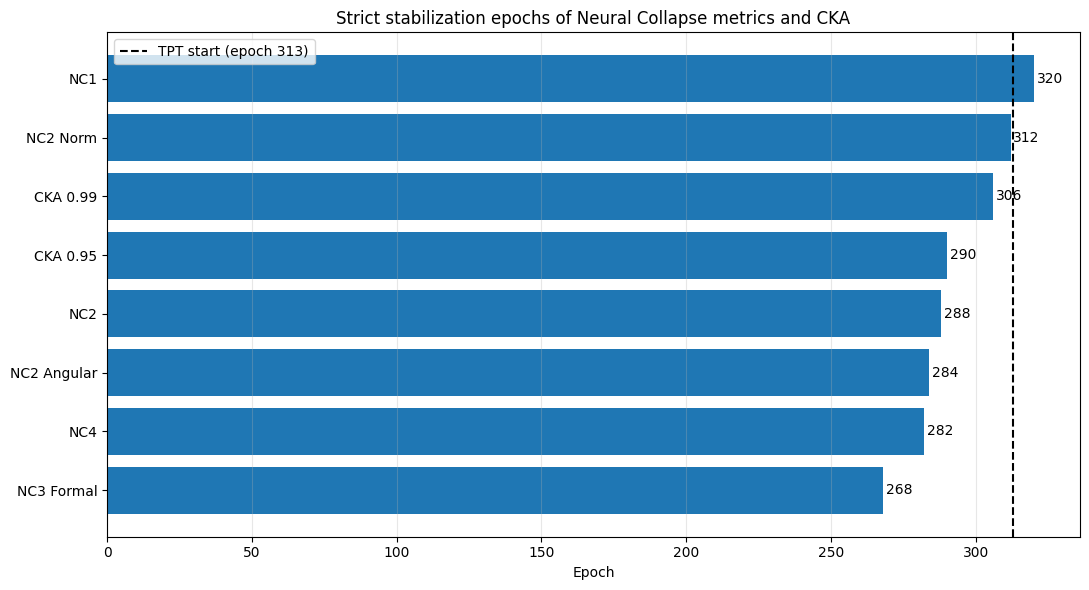

In [5]:
plot_df = stab.sort_values("Stabilization Epoch")

plt.figure(figsize=(11, 6))
plt.barh(plot_df["Metric"], plot_df["Stabilization Epoch"])
plt.axvline(TPT_EPOCH, color="k", linestyle="--", label=f"TPT start (epoch {TPT_EPOCH})")
for y, e in enumerate(plot_df["Stabilization Epoch"]):
    plt.text(e + 1, y, str(e), va="center")
plt.xlabel("Epoch")
plt.title("Strict stabilization epochs of Neural Collapse metrics and CKA")
plt.grid(axis="x", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "stabilization_epochs.png", dpi=200)
plt.show()

## Progress toward the final state
Each curve is rescaled so that 0 = value at epoch 1 and 1 = value at epoch 350, which makes metrics with different scales and directions comparable.

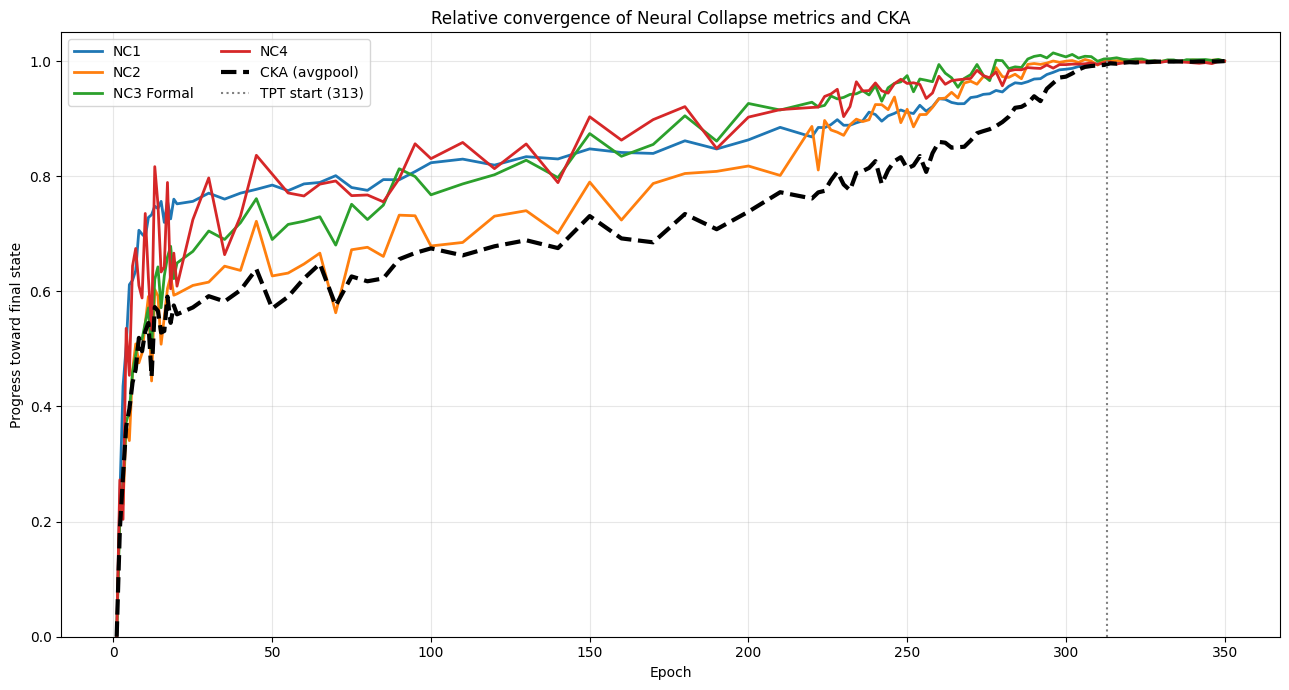

In [6]:
progress = pd.DataFrame({"epoch": df["epoch"]})
for label, col in [("NC1", "NC1"), ("NC2", "NC2"), ("NC3 Formal", "NC3_formal"), ("NC4", "NC4"), ("CKA", "CKA")]:
    first, last = df[col].iloc[0], df[col].iloc[-1]
    progress[label] = (first - df[col]) / (first - last)   # same formula works for both directions

plt.figure(figsize=(13, 7))
for label in ["NC1", "NC2", "NC3 Formal", "NC4"]:
    plt.plot(progress["epoch"], progress[label], linewidth=2, label=label)
plt.plot(progress["epoch"], progress["CKA"], linewidth=3, linestyle="--", color="k", label="CKA (avgpool)")
plt.axvline(TPT_EPOCH, color="gray", linestyle=":", label=f"TPT start ({TPT_EPOCH})")
plt.xlabel("Epoch")
plt.ylabel("Progress toward final state")
plt.title("Relative convergence of Neural Collapse metrics and CKA")
plt.ylim(0, 1.05)
plt.grid(True, alpha=0.3)
plt.legend(ncol=2)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "relative_convergence.png", dpi=200)
plt.show()

## Neural Collapse metrics around the start of the Terminal Phase of Training

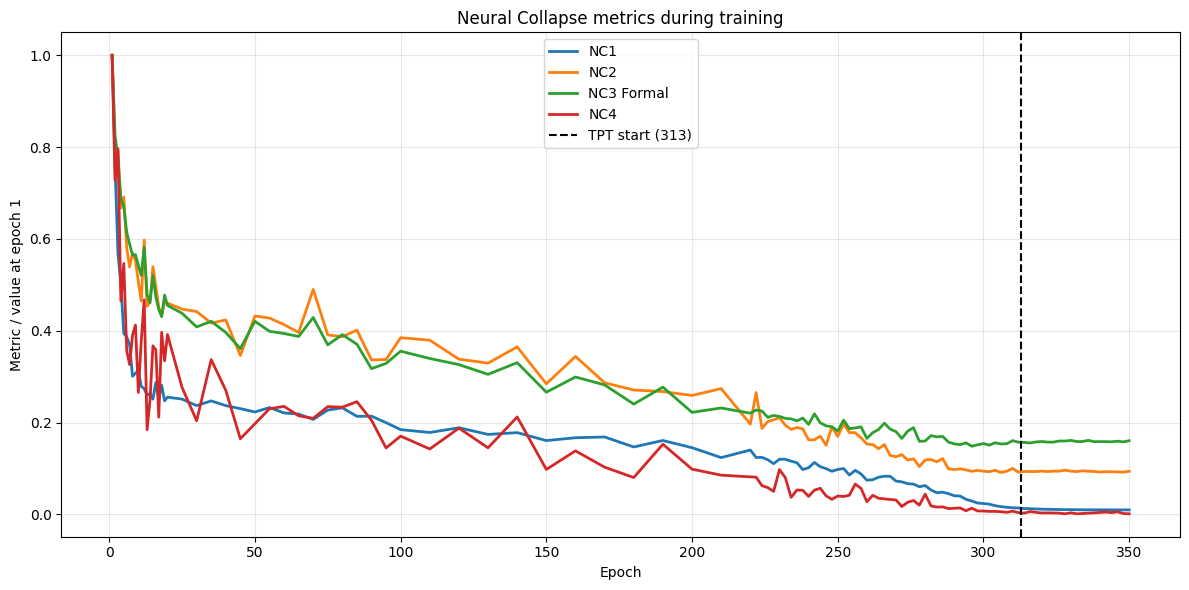

In [7]:
fig, ax = plt.subplots(figsize=(12, 6))
for label, col in [("NC1", "NC1"), ("NC2", "NC2"), ("NC3 Formal", "NC3_formal"), ("NC4", "NC4")]:
    ax.plot(df["epoch"], df[col] / df[col].iloc[0], linewidth=2, label=label)
ax.axvline(TPT_EPOCH, color="k", linestyle="--", label=f"TPT start ({TPT_EPOCH})")
ax.set_xlabel("Epoch")
ax.set_ylabel("Metric / value at epoch 1")
ax.set_title("Neural Collapse metrics during training")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "nc_metrics_with_tpt.png", dpi=200)
plt.show()